## **Import Library & Data**

### Import Library

In [ ]:
import warnings
warnings.filterwarnings(action="ignore", message=r"datetime.datetime.utcnow")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

### Import Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os
os.chdir('drive/MyDrive/Skripsi')

In [ ]:
# ── File Harian ──────────────────────────────────────────────────────────────
file_harian = 'data harian.xlsx'

df_harga   = pd.read_excel(file_harian, sheet_name='Harga')   # Data harga
df_iklim   = pd.read_excel(file_harian, sheet_name='Iklim')   # Data iklim

# ── File Inflasi Bulanan ─────────────────────────────────────────────────────
df_inflasi = pd.read_excel('inflasi sm bulanan.xlsx')

# ── Preview ──────────────────────────────────────────────────────────────────
print(df_harga.head())
print(df_iklim.head())
print(df_inflasi.head())

     Tanggal    Beras  Daging Ayam  Daging Sapi  Telur Ayam  Bawang Merah  \
0 2018-01-01  11050.0      35650.0     115850.0     25200.0       21900.0   
1 2018-01-02  11750.0      34800.0     114200.0     26650.0       26300.0   
2 2018-01-03  11750.0      34750.0     113650.0     26450.0       26300.0   
3 2018-01-04  11750.0      34400.0     114250.0     26200.0       26300.0   
4 2018-01-05  11800.0      34550.0     114250.0     26100.0       26350.0   

   Bawang Putih  Cabai Merah  Cabai Rawit  Minyak Goreng  Gula Pasir  
0       22400.0      37100.0      41700.0        13000.0     13550.0  
1       24100.0      38700.0      44350.0        13800.0     14250.0  
2       24150.0      38950.0      45000.0        13850.0     14250.0  
3       24250.0      38600.0      45550.0        13850.0     14250.0  
4       24150.0      38450.0      45500.0        13800.0     14250.0  
     Tanggal  Suhu Maksimum  Suhu Minimum  Curah Hujan  Kelembapan  \
0 2018-01-01          26.89         23.30

## **EDA**

In [ ]:
df_harga.info()
df_iklim.info()
df_inflasi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3047 entries, 0 to 3046
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Tanggal        3047 non-null   datetime64[ns]
 1   Beras          2160 non-null   float64       
 2   Daging Ayam    2160 non-null   float64       
 3   Daging Sapi    2160 non-null   float64       
 4   Telur Ayam     2160 non-null   float64       
 5   Bawang Merah   2160 non-null   float64       
 6   Bawang Putih   2160 non-null   float64       
 7   Cabai Merah    2160 non-null   float64       
 8   Cabai Rawit    2160 non-null   float64       
 9   Minyak Goreng  2160 non-null   float64       
 10  Gula Pasir     2160 non-null   float64       
dtypes: datetime64[ns](1), float64(10)
memory usage: 262.0 KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3047 entries, 0 to 3046
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype         


In [ ]:
df_harga.describe()

,Tanggal,Beras,Daging Ayam,Daging Sapi,Telur Ayam,Bawang Merah,Bawang Putih,Cabai Merah,Cabai Rawit,Minyak Goreng,Gula Pasir
count,3047,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000
mean,2022-03-03 23:59:59.999999744,13093.981481,35885.972222,127263.703704,27767.037037,37083.611111,34961.481481,45518.888889,51281.944444,17294.606481,15805.046296
min,2018-01-01 00:00:00,9600.000000,26500.000000,100650.000000,18250.000000,21400.000000,21500.000000,17500.000000,17050.000000,11600.000000,12000.000000
25%,2020-02-01 12:00:00,11750.000000,34200.000000,118150.000000,25150.000000,31050.000000,29250.000000,37000.000000,41000.000000,13750.000000,14050.000000
50%,2022-03-04 00:00:00,11900.000000,35700.000000,127825.000000,28050.000000,36600.000000,33125.000000,44250.000000,49450.000000,18800.000000,15100.000000
75%,2024-04-03 12:00:00,15200.000000,37550.000000,135200.000000,30200.000000,41800.000000,41012.500000,52150.000000,59662.500000,19750.000000,18350.000000
max,2026-05-05 00:00:00,16000.000000,52100.000000,157500.000000,53250.000000,64800.000000,67500.000000,89050.000000,91750.000000,25700.000000,19650.000000
std,NaN,1671.185488,2666.298942,9160.513702,3062.193300,8016.568208,7175.320695,11261.806307,13120.174153,3323.747464,2091.274136


In [ ]:
df_iklim.describe()

,Tanggal,Suhu Maksimum,Suhu Minimum,Curah Hujan,Kelembapan,Kecepatan Angin Maksimum,Kecepatan Angin Minimum
count,3047,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000
mean,2022-03-03 23:59:59.999999744,28.772081,23.231037,8.734749,19.057053,1.093659,0.216134
min,2018-01-01 00:00:00,24.830000,19.140000,0.000000,14.860000,0.570000,0.000000
25%,2020-02-01 12:00:00,28.110000,22.780000,1.380000,18.600000,1.000000,0.120000
50%,2022-03-04 00:00:00,28.880000,23.270000,4.880000,19.070000,1.100000,0.210000
75%,2024-04-03 12:00:00,29.520000,23.740000,11.670000,19.550000,1.200000,0.300000
max,2026-05-05 00:00:00,31.430000,25.580000,196.000000,21.570000,1.600000,0.620000
std,NaN,1.034363,0.762675,11.475384,0.796120,0.145457,0.114574


In [ ]:
df_inflasi.describe()

,Tahun,Tanggal,Inflasi Subkelompok Makanan
count,100.000000,100,100.000000
mean,2021.680000,2022-03-15 12:00:00,1.097500
min,2018.000000,2018-01-01 00:00:00,-2.350000
25%,2020.000000,2020-02-07 06:00:00,0.107500
50%,2022.000000,2022-03-15 12:00:00,0.830000
75%,2024.000000,2024-04-20 18:00:00,1.765000
max,2026.000000,2026-05-28 00:00:00,8.090000
std,2.424121,NaN,1.893666


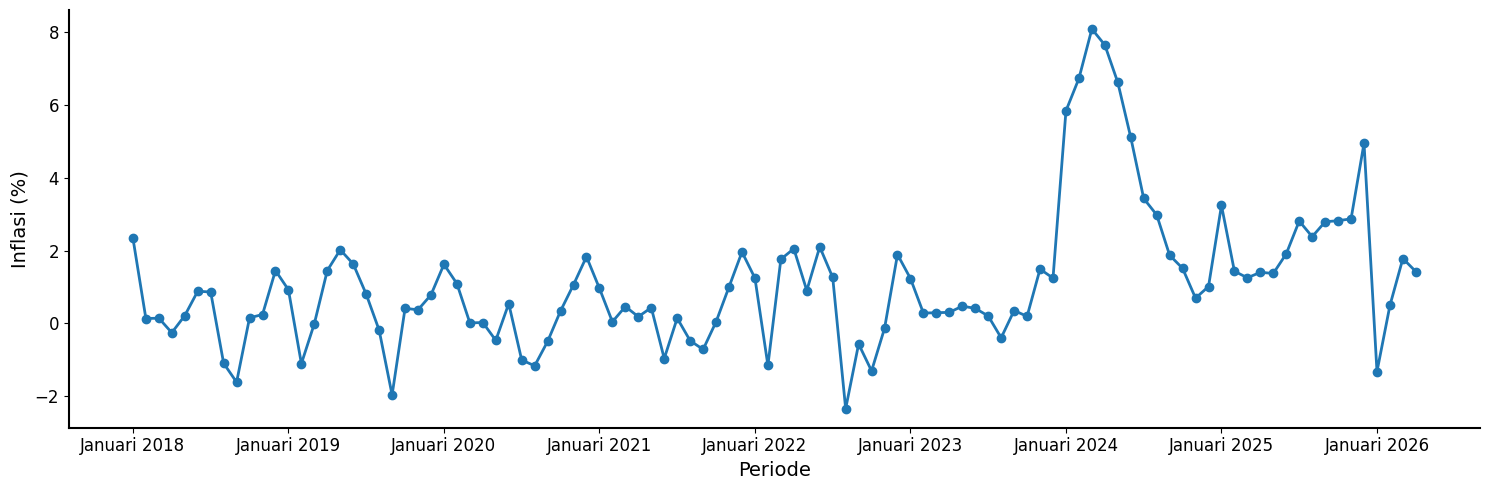

In [ ]:
import matplotlib.pyplot as plt

# Label periode
df_inflasi["Periode"] = (
    df_inflasi["Bulan"] + " " + df_inflasi["Tahun"].astype(str)
)

# Filter for January entries to display annually
january_entries = df_inflasi[df_inflasi['Bulan'] == 'Januari']
january_ticks = january_entries.index.tolist()
january_labels = january_entries["Periode"].tolist()

# Plot
plt.figure(figsize=(15,5))
plt.plot(
    df_inflasi["Periode"],
    df_inflasi["Inflasi Subkelompok Makanan"],
    marker="o",
    linewidth=2,
    label="Inflasi"
)


# plt.title("Perkembangan Inflasi Subkelompok Makanan") # Removed title
ax = plt.gca()

plt.xlabel("Periode", fontsize=14)
plt.ylabel("Inflasi (%)", fontsize=14)

plt.xticks(
    ticks=january_ticks,
    labels=january_labels,
    rotation=0,
    ha="center"
)

ax.tick_params(axis="x", labelsize=12)
ax.tick_params(axis="y", labelsize=12)
# ==========================================
# SETENGAH BOX
# ==========================================

# Hilangkan garis atas dan kanan
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Pertahankan garis kiri (Y) dan bawah (X)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# Ketebalan garis
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

# Warna garis
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')

plt.tight_layout()
plt.show()

## **Cleaning**

In [ ]:
# --- Format Tanggal Data Harian ---
df_harga.rename(columns={'Tahun': 'Tanggal'}, inplace=True)
df_harga['Tanggal'] = pd.to_datetime(df_harga['Tanggal'], errors='coerce')
df_harga.set_index('Tanggal', inplace=True)
df_harga = df_harga.apply(pd.to_numeric, errors='coerce')

df_iklim['Tanggal'] = pd.to_datetime(df_iklim['Tanggal'], errors='coerce')
df_iklim.set_index('Tanggal', inplace=True)
df_iklim = df_iklim.apply(pd.to_numeric, errors='coerce')

In [ ]:
# Memastikan index tanggal penuh setiap harinya agar tidak ada hari bolong
start_dt = max(df_harga.index.min(), df_iklim.index.min())
end_dt = min(df_harga.index.max(), df_iklim.index.max())
full_idx = pd.date_range(start_dt, end_dt, freq='D')

df_harga = df_harga.reindex(full_idx).fillna(method='ffill').fillna(method='bfill')
df_iklim = df_iklim.reindex(full_idx).fillna(method='ffill').fillna(method='bfill')

/tmp/ipykernel_749/2832138809.py:6: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_harga = df_harga.reindex(full_idx).fillna(method='ffill').fillna(method='bfill')
/tmp/ipykernel_749/2832138809.py:7: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_iklim = df_iklim.reindex(full_idx).fillna(method='ffill').fillna(method='bfill')


In [ ]:
# --- Persentase Perubahan Harga Harian ---
df_harga_pct = df_harga.pct_change().fillna(0)

In [ ]:
# ==========================================
# KONVERSI FORMAT MIDAS (Pecah 7 Hari)
# ==========================================
# Beri tanda Tahun-Minggu ISO dan Hari dalam Minggu (1=Senin, 7=Minggu)
df_harga_pct['ISO_YearWeek'] = df_harga_pct.index.map(lambda x: f"{x.isocalendar()[0]}-W{x.isocalendar()[1]:02d}")
df_harga_pct['DayOfWeek'] = df_harga_pct.index.isocalendar().day

df_iklim['ISO_YearWeek'] = df_iklim.index.map(lambda x: f"{x.isocalendar()[0]}-W{x.isocalendar()[1]:02d}")
df_iklim['DayOfWeek'] = df_iklim.index.isocalendar().day

# Pivot Data: Murni memindahkan baris harian menjadi kolom
X_harga_midas = df_harga_pct.pivot(index='ISO_YearWeek', columns='DayOfWeek')
X_harga_midas.columns = [f"{col[0]}_Hari_{col[1]}" for col in X_harga_midas.columns]

X_iklim_midas = df_iklim.pivot(index='ISO_YearWeek', columns='DayOfWeek')
X_iklim_midas.columns = [f"{col[0]}_Hari_{col[1]}" for col in X_iklim_midas.columns]

In [ ]:
# --- Preprocessing Y (Bulanan ke Mingguan tanpa Resample) ---
bulan_map = {'Januari':1, 'Februari':2, 'Maret':3, 'April':4, 'Mei':5, 'Juni':6,
             'Juli':7, 'Agustus':8, 'September':9, 'Oktober':10, 'November':11, 'Desember':12}
df_inflasi['Bulan_Num'] = df_inflasi['Bulan'].map(bulan_map)

# Buat dataframe penampung untuk setiap minggu yang ada di X_harga_midas
y_weekly_df = pd.DataFrame(index=X_harga_midas.index)

# Tentukan bulan dan tahun untuk setiap ISO_YearWeek
# Mengambil hari Kamis (Day 4) dari setiap minggu ISO untuk menentukan minggu tersebut jatuh di bulan apa
def get_month_year_from_isoweek(iso_week_str):
    year, week = int(iso_week_str.split('-W')[0]), int(iso_week_str.split('-W')[1])
    # Menggunakan datetime dari ISO calendar
    dt = pd.to_datetime(f"{year}-W{week}-4", format="%G-W%V-%u")
    return dt.year, dt.month

y_weekly_df['Tahun'] = y_weekly_df.index.map(lambda x: get_month_year_from_isoweek(x)[0])
y_weekly_df['Bulan_Num'] = y_weekly_df.index.map(lambda x: get_month_year_from_isoweek(x)[1])

# Merge dengan nilai Inflasi aktual dari data bulanan
y_weekly_df = y_weekly_df.reset_index().merge(df_inflasi[['Tahun', 'Bulan_Num', 'Inflasi Subkelompok Makanan']],
                                             on=['Tahun', 'Bulan_Num'],
                                             how='left').set_index('ISO_YearWeek')

# Lakukan interpolasi agar nilainya tidak sekadar copy-paste datar
y_weekly_df['Inflasi Subkelompok Makanan'] = y_weekly_df['Inflasi Subkelompok Makanan'].interpolate(method='linear')

## **Skema Input Variabel**

In [ ]:
# ==========================================
# 2. SKEMA INPUT VARIABEL (3 Skenario)
# ==========================================
# Gabungkan semua data, pastikan sejajar berdasarkan ISO_YearWeek
df_master = pd.concat([y_weekly_df[['Inflasi Subkelompok Makanan']], X_iklim_midas, X_harga_midas], axis=1).dropna()

X_iklim = df_master[X_iklim_midas.columns]
X_harga = df_master[X_harga_midas.columns]
X_kombinasi = df_master[list(X_iklim_midas.columns) + list(X_harga_midas.columns)]
Y = df_master['Inflasi Subkelompok Makanan']

## **Evaluasi**


MENJALANKAN SKENARIO 1 (IKLIM) (MURNI HARIAN)
--- Evaluasi MIDAS BASIC - Skenario 1 (Iklim) ---
RMSE : 1.7635 | MAE : 1.3902 | MAPE : 75.4862% | sMAPE : 90.8148%
--- Evaluasi XGBOOST ML - Skenario 1 (Iklim) ---
RMSE : 1.6677 | MAE : 1.3679 | MAPE : 65.1912% | sMAPE : 91.2327%


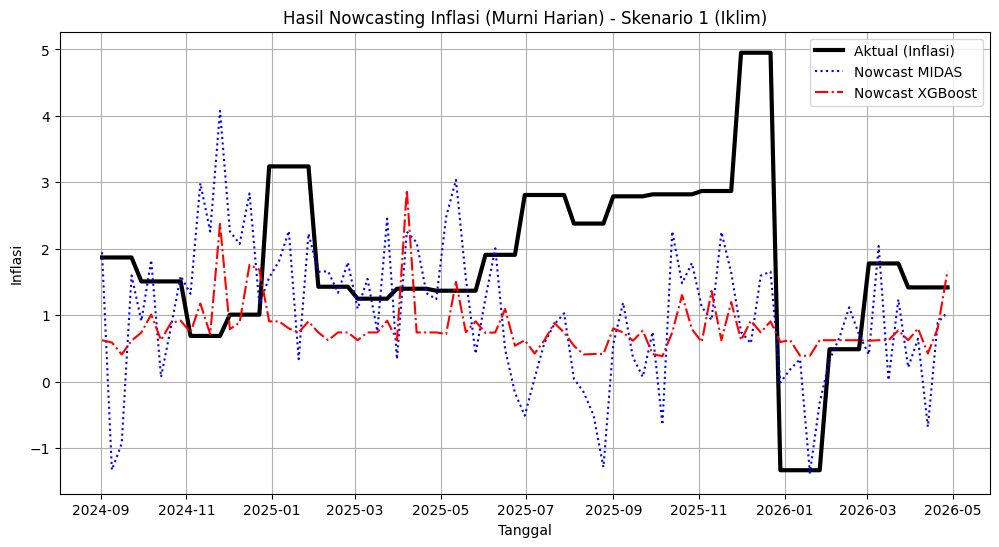


MENJALANKAN SKENARIO 2 (HARGA) (MURNI HARIAN)
--- Evaluasi MIDAS BASIC - Skenario 2 (Harga) ---
RMSE : 1.4960 | MAE : 1.1509 | MAPE : 56.8724% | sMAPE : 71.9864%
--- Evaluasi XGBOOST ML - Skenario 2 (Harga) ---
RMSE : 1.4564 | MAE : 1.1143 | MAPE : 55.5117% | sMAPE : 66.9107%


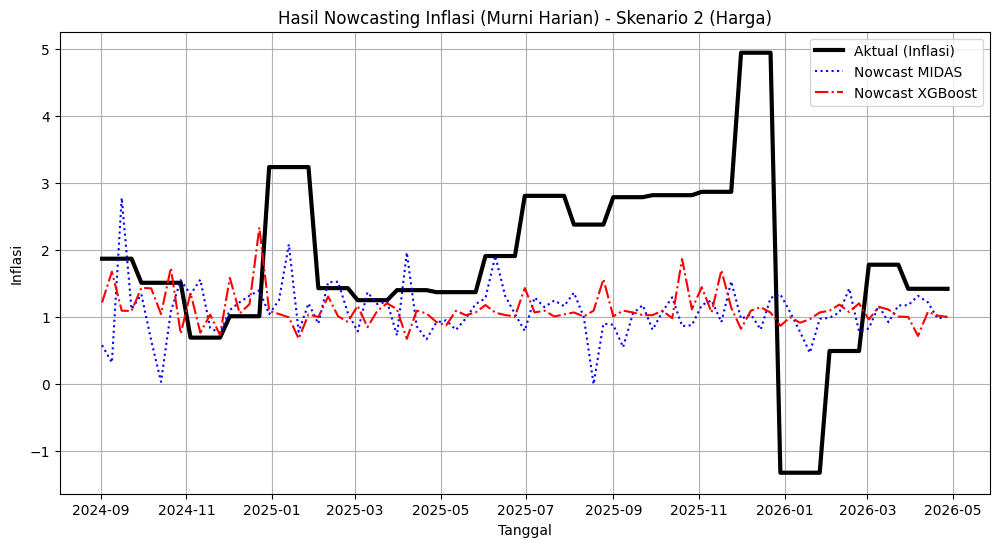


MENJALANKAN SKENARIO 3 (KOMBINASI) (MURNI HARIAN)
--- Evaluasi MIDAS BASIC - Skenario 3 (Kombinasi) ---
RMSE : 1.8336 | MAE : 1.4597 | MAPE : 82.5111% | sMAPE : 92.0806%
--- Evaluasi XGBOOST ML - Skenario 3 (Kombinasi) ---
RMSE : 1.7162 | MAE : 1.4192 | MAPE : 68.4528% | sMAPE : 98.2946%


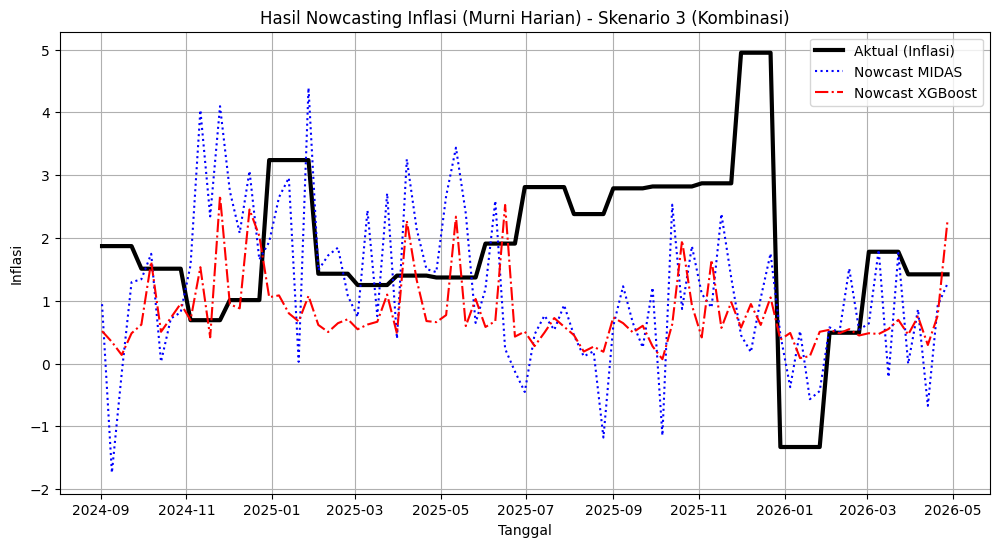

In [ ]:
# ==========================================
# FUNGSI EVALUASI
# ==========================================
def evaluate_model(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    smape = np.mean(2.0 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)) * 100
    print(f"--- Evaluasi {model_name} ---")
    print(f"RMSE : {rmse:.4f} | MAE : {mae:.4f} | MAPE : {mape:.4f}% | sMAPE : {smape:.4f}%")
    return {'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'sMAPE': smape}

hasil_evaluasi = []
skenario_dict = {"Skenario 1 (Iklim)": X_iklim, "Skenario 2 (Harga)": X_harga, "Skenario 3 (Kombinasi)": X_kombinasi}

# Menyimpan model XGBoost terbaik setiap skenario
model_xgb_dict = {}

# Menyimpan data setiap skenario untuk SHAP
data_xgb_dict = {}

for nama_skenario, X_data in skenario_dict.items():
    print(f"\n{'='*70}\nMENJALANKAN {nama_skenario.upper()} (MURNI HARIAN)\n{'='*70}")

    data_model = pd.concat([Y, X_data], axis=1).dropna()
    Y_clean = data_model.iloc[:, 0]
    X_clean = data_model.iloc[:, 1:]

    # 4. SPLITTING DATA (80:20)
    split_idx = int(len(data_model) * 0.8)
    X_train, X_test = X_clean.iloc[:split_idx], X_clean.iloc[split_idx:]
    y_train, y_test = Y_clean.iloc[:split_idx], Y_clean.iloc[split_idx:]

    # NORMALISASI
    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), index=X_train.index, columns=X_train.columns)
    X_test_scaled = pd.DataFrame(scaler.transform(X_test), index=X_test.index, columns=X_test.columns)

    # ------------------------------------------
    # MODEL 1: MIDAS BASIC (U-MIDAS dg OLS)
    # ------------------------------------------
    X_train_midas = sm.add_constant(X_train_scaled)
    X_test_midas = sm.add_constant(X_test_scaled)

    model_midas = sm.OLS(y_train, X_train_midas).fit()
    y_pred_midas = model_midas.predict(X_test_midas)
    eval_midas = evaluate_model(y_test, y_pred_midas, f"MIDAS BASIC - {nama_skenario}")

    tscv = TimeSeriesSplit(n_splits=5)

    # ------------------------------------------
    # MODEL 2: XGBOOST
    # ------------------------------------------
    param_grid_xgb = {'n_estimators': [50, 100, 200], 'max_depth': [2, 3, 5], 'learning_rate': [0.01, 0.05, 0.1]}
    xgb_model = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)
    grid_search_xgb = GridSearchCV(estimator=xgb_model, param_grid=param_grid_xgb, cv=tscv, scoring='neg_root_mean_squared_error', verbose=0, n_jobs=-1)
    grid_search_xgb.fit(X_train_scaled, y_train)

    best_xgb = grid_search_xgb.best_estimator_
    y_pred_xgb = best_xgb.predict(X_test_scaled)

    # Simpan model terbaik untuk setiap skenario
    model_xgb_dict[nama_skenario] = best_xgb

    # Simpan data untuk SHAP
    data_xgb_dict[nama_skenario] = {
        "X_train": X_train_scaled.copy(),
        "X_test": X_test_scaled.copy(),
        "y_train": y_train.copy(),
        "y_test": y_test.copy()
    }

    eval_xgb = evaluate_model(y_test, y_pred_xgb, f"XGBOOST ML - {nama_skenario}")


    # Menyimpan evaluasi
    hasil_evaluasi.append({
        'Skenario': nama_skenario,
        'MIDAS_RMSE': eval_midas['RMSE'], 'XGB_RMSE': eval_xgb['RMSE'],
        'MIDAS_MAE': eval_midas['MAE'], 'XGB_MAE': eval_xgb['MAE'],
        'MIDAS_MAPE': eval_midas['MAPE'], 'XGB_MAPE': eval_xgb['MAPE'],
        'MIDAS_sMAPE': eval_midas['sMAPE'], 'XGB_sMAPE': eval_xgb['sMAPE']
    })

    # 10. NOWCASTING (Visualisasi Output)
    # Konversi string ISO Week kembali ke tanggal untuk keperluan plot grafik
    plot_dates = pd.to_datetime(y_test.index.map(lambda x: f"{x[:4]}-W{x[-2:]}-1"), format="%G-W%V-%u")

    plt.figure(figsize=(12, 6))
    plt.plot(plot_dates, y_test.values, label='Aktual (Inflasi)', color='black', linewidth=3)
    plt.plot(plot_dates, y_pred_midas, label='Nowcast MIDAS', color='blue', linestyle=':')
    plt.plot(plot_dates, y_pred_xgb, label='Nowcast XGBoost', color='red', linestyle='-.')

    plt.title(f'Hasil Nowcasting Inflasi (Murni Harian) - {nama_skenario}')
    plt.xlabel('Tanggal')
    plt.ylabel('Inflasi')
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
# 9. MEMBANDINGKAN MODEL
print("\n" + "="*80)
print("KESIMPULAN PERBANDINGAN MODEL (Evaluasi Metrik)")
print("="*80)
df_perbandingan = pd.DataFrame(hasil_evaluasi)
print(df_perbandingan.to_string(index=False))


KESIMPULAN PERBANDINGAN MODEL (Evaluasi Metrik)
              Skenario  MIDAS_RMSE  XGB_RMSE  MIDAS_MAE  XGB_MAE  MIDAS_MAPE  XGB_MAPE  MIDAS_sMAPE  XGB_sMAPE
    Skenario 1 (Iklim)    1.763531  1.667653   1.390172 1.367878   75.486169 65.191225    90.814832  91.232747
    Skenario 2 (Harga)    1.495974  1.456444   1.150884 1.114278   56.872358 55.511711    71.986426  66.910742
Skenario 3 (Kombinasi)    1.833632  1.716182   1.459721 1.419247   82.511126 68.452804    92.080570  98.294612


# COBA COBA

In [ ]:
# ==========================================
# FUNGSI EVALUASI
# ==========================================
def evaluate_model(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    smape = np.mean(2.0 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)) * 100
    print(f"--- Evaluasi {model_name} ---")
    print(f"RMSE : {rmse:.4f} | MAE : {mae:.4f} | MAPE : {mape:.4f}% | sMAPE : {smape:.4f}%")
    return {'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'sMAPE': smape}


# ============================================================
# PERSIAPAN MODEL DAN PENYIMPANAN HASIL
# ============================================================

hasil_evaluasi = []

skenario_dict = {
    "Skenario 1 (Iklim)": X_iklim,
    "Skenario 2 (Harga)": X_harga,
    "Skenario 3 (Kombinasi)": X_kombinasi
}

# Menyimpan model untuk setiap skenario
model_midas_dict = {}
model_xgb_dict = {}

# Menyimpan data test
data_test_dict = {}

# Menyimpan hasil prediksi
prediksi_dict = {}

# ============================================================
# PEMODELAN MIDAS DAN XGBOOST
# ============================================================

for nama_skenario, X_data in skenario_dict.items():

    print(
        f"\n{'='*70}\n"
        f"MENJALANKAN {nama_skenario.upper()}\n"
        f"{'='*70}"
    )

    # --------------------------------------------------------
    # 1. GABUNGKAN Y DAN X
    # --------------------------------------------------------

    data_model = pd.concat(
        [Y, X_data],
        axis=1
    ).dropna()

    Y_clean = data_model.iloc[:, 0]
    X_clean = data_model.iloc[:, 1:]


    # --------------------------------------------------------
    # 2. SPLITTING DATA 80:20
    # --------------------------------------------------------

    split_idx = int(len(data_model) * 0.8)

    X_train = X_clean.iloc[:split_idx]
    X_test = X_clean.iloc[split_idx:]

    y_train = Y_clean.iloc[:split_idx]
    y_test = Y_clean.iloc[split_idx:]


    # --------------------------------------------------------
    # 3. NORMALISASI
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = pd.DataFrame(
        scaler.fit_transform(X_train),
        index=X_train.index,
        columns=X_train.columns
    )

    X_test_scaled = pd.DataFrame(
        scaler.transform(X_test),
        index=X_test.index,
        columns=X_test.columns
    )


    # --------------------------------------------------------
    # 4. MODEL MIDAS BASIC
    # --------------------------------------------------------

    X_train_midas = sm.add_constant(X_train_scaled)
    X_test_midas = sm.add_constant(X_test_scaled)

    model_midas = sm.OLS(
        y_train,
        X_train_midas
    ).fit()

    y_pred_midas = model_midas.predict(
        X_test_midas
    )

    eval_midas = evaluate_model(
        y_test,
        y_pred_midas,
        f"MIDAS - {nama_skenario}"
    )


    # Simpan model MIDAS
    model_midas_dict[nama_skenario] = model_midas


    # --------------------------------------------------------
    # 5. XGBOOST + TIME SERIES CROSS VALIDATION
    # --------------------------------------------------------

    tscv = TimeSeriesSplit(
        n_splits=5
    )

    param_grid_xgb = {
        "n_estimators": [50, 100, 200],
        "max_depth": [2, 3, 5],
        "learning_rate": [0.01, 0.05, 0.1]
    }

    xgb_model = xgb.XGBRegressor(
        objective="reg:squarederror",
        random_state=42
    )

    grid_search_xgb = GridSearchCV(
        estimator=xgb_model,
        param_grid=param_grid_xgb,
        cv=tscv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    grid_search_xgb.fit(
        X_train_scaled,
        y_train
    )


    # Model XGBoost terbaik
    best_xgb = grid_search_xgb.best_estimator_

    y_pred_xgb = best_xgb.predict(
        X_test_scaled
    )

    eval_xgb = evaluate_model(
        y_test,
        y_pred_xgb,
        f"XGBoost - {nama_skenario}"
    )


    # --------------------------------------------------------
    # 6. SIMPAN MODEL DAN DATA UNTUK SHAP
    # --------------------------------------------------------

    model_xgb_dict[nama_skenario] = best_xgb

    data_test_dict[nama_skenario] = {
        "X_train": X_train_scaled.copy(),
        "X_test": X_test_scaled.copy(),
        "y_train": y_train.copy(),
        "y_test": y_test.copy()
    }


    # --------------------------------------------------------
    # 7. SIMPAN PREDIKSI
    # --------------------------------------------------------

    prediksi_dict[
        (nama_skenario, "MIDAS")
    ] = y_pred_midas

    prediksi_dict[
        (nama_skenario, "XGBoost")
    ] = y_pred_xgb


    # --------------------------------------------------------
    # 8. SIMPAN HASIL EVALUASI
    # --------------------------------------------------------

    hasil_evaluasi.append({
        "Skenario": nama_skenario,

        "MIDAS_RMSE": eval_midas["RMSE"],
        "MIDAS_MAE": eval_midas["MAE"],
        "MIDAS_MAPE": eval_midas["MAPE"],
        "MIDAS_sMAPE": eval_midas["sMAPE"],

        "XGB_RMSE": eval_xgb["RMSE"],
        "XGB_MAE": eval_xgb["MAE"],
        "XGB_MAPE": eval_xgb["MAPE"],
        "XGB_sMAPE": eval_xgb["sMAPE"]
    })


MENJALANKAN SKENARIO 1 (IKLIM)
--- Evaluasi MIDAS - Skenario 1 (Iklim) ---
RMSE : 1.7635 | MAE : 1.3902 | MAPE : 75.4862% | sMAPE : 90.8148%
--- Evaluasi XGBoost - Skenario 1 (Iklim) ---
RMSE : 1.6677 | MAE : 1.3679 | MAPE : 65.1912% | sMAPE : 91.2327%

MENJALANKAN SKENARIO 2 (HARGA)
--- Evaluasi MIDAS - Skenario 2 (Harga) ---
RMSE : 1.4960 | MAE : 1.1509 | MAPE : 56.8724% | sMAPE : 71.9864%
--- Evaluasi XGBoost - Skenario 2 (Harga) ---
RMSE : 1.4564 | MAE : 1.1143 | MAPE : 55.5117% | sMAPE : 66.9107%

MENJALANKAN SKENARIO 3 (KOMBINASI)
--- Evaluasi MIDAS - Skenario 3 (Kombinasi) ---
RMSE : 1.8336 | MAE : 1.4597 | MAPE : 82.5111% | sMAPE : 92.0806%
--- Evaluasi XGBoost - Skenario 3 (Kombinasi) ---
RMSE : 1.7162 | MAE : 1.4192 | MAPE : 68.4528% | sMAPE : 98.2946%


In [ ]:
# ============================================================
# TABEL PERBANDINGAN MODEL
# ============================================================

# Convert the list of dictionaries to a DataFrame first
df_evaluasi = pd.DataFrame(hasil_evaluasi)

hasil_perbandingan = pd.concat([

    df_evaluasi[
        [
            "Skenario",
            "MIDAS_RMSE",
            "MIDAS_MAE",
            "MIDAS_MAPE",
            "MIDAS_sMAPE"
        ]
    ].rename(columns={
        "MIDAS_RMSE": "RMSE",
        "MIDAS_MAE": "MAE",
        "MIDAS_MAPE": "MAPE",
        "MIDAS_sMAPE": "sMAPE"
    }).assign(
        Model="MIDAS"
    ),

    df_evaluasi[
        [
            "Skenario",
            "XGB_RMSE",
            "XGB_MAE",
            "XGB_MAPE",
            "XGB_sMAPE"
        ]
    ].rename(columns={
        "XGB_RMSE": "RMSE",
        "XGB_MAE": "MAE",
        "XGB_MAPE": "MAPE",
        "XGB_sMAPE": "sMAPE"
    }).assign(
        Model="XGBoost"
    )

], ignore_index=True)


# Urutkan berdasarkan RMSE terkecil
hasil_perbandingan = hasil_perbandingan.sort_values(
    "RMSE"
).reset_index(drop=True)


print("\n" + "="*80)
print("PERBANDINGAN MODEL BERDASARKAN RMSE")
print("="*80)

display(hasil_perbandingan)


PERBANDINGAN MODEL BERDASARKAN RMSE


,Skenario,RMSE,MAE,MAPE,sMAPE,Model
0,Skenario 2 (Harga),1.456444,1.114278,55.511711,66.910742,XGBoost
1,Skenario 2 (Harga),1.495974,1.150884,56.872358,71.986426,MIDAS
2,Skenario 1 (Iklim),1.667653,1.367878,65.191225,91.232747,XGBoost
3,Skenario 3 (Kombinasi),1.716182,1.419247,68.452804,98.294612,XGBoost
4,Skenario 1 (Iklim),1.763531,1.390172,75.486169,90.814832,MIDAS
5,Skenario 3 (Kombinasi),1.833632,1.459721,82.511126,92.080570,MIDAS


In [ ]:
# ============================================================
# PEMILIHAN MODEL TERBAIK
# ============================================================

model_terbaik = hasil_perbandingan.iloc[0]

nama_model_terbaik = model_terbaik["Model"]
nama_skenario_terbaik = model_terbaik["Skenario"]

print("\n" + "="*80)
print("MODEL TERBAIK")
print("="*80)

print("Model    :", nama_model_terbaik)
print("Skenario :", nama_skenario_terbaik)
print("RMSE     :", round(model_terbaik["RMSE"], 4))
print("MAE      :", round(model_terbaik["MAE"], 4))
print("MAPE     :", round(model_terbaik["MAPE"], 4), "%")
print("sMAPE    :", round(model_terbaik["sMAPE"], 4), "%")


MODEL TERBAIK
Model    : XGBoost
Skenario : Skenario 2 (Harga)
RMSE     : 1.4564
MAE      : 1.1143
MAPE     : 55.5117 %
sMAPE    : 66.9107 %


In [ ]:
# ============================================================
# NOWCASTING MENGGUNAKAN MODEL TERBAIK
# ============================================================

X_test_terbaik = data_test_dict[
    nama_skenario_terbaik
]["X_test"]

y_test_terbaik = data_test_dict[
    nama_skenario_terbaik
]["y_test"
].copy()

tanggal_test = pd.to_datetime(
    y_test_terbaik.index.map(
        lambda x: f"{x[:4]}-W{x[-2:]}-1"
    ),
    format="%G-W%V-%u"
)


# Ambil prediksi model terbaik
prediksi_terbaik = prediksi_dict[
    (
        nama_skenario_terbaik,
        nama_model_terbaik
    )
]


# ============================================================
# HASIL NOWCASTING
# ============================================================

hasil_nowcasting = pd.DataFrame({
    "tanggal_minggu": tanggal_test,
    "aktual": y_test_terbaik.values,
    "nowcasting": np.asarray(prediksi_terbaik)
})


# Tambahkan informasi tahun dan bulan
hasil_nowcasting["tahun"] = (
    hasil_nowcasting["tanggal_minggu"].dt.year
)

hasil_nowcasting["bulan"] = (
    hasil_nowcasting["tanggal_minggu"].dt.month
)

hasil_nowcasting["minggu_ke"] = (
    hasil_nowcasting
    .groupby(["tahun", "bulan"])
    .cumcount() + 1
)


print("\n" + "="*80)
print("HASIL NOWCASTING MODEL TERBAIK")
print("="*80)

print("Model    :", nama_model_terbaik)
print("Skenario :", nama_skenario_terbaik)

display(
    hasil_nowcasting.head(10)
)


HASIL NOWCASTING MODEL TERBAIK
Model    : XGBoost
Skenario : Skenario 2 (Harga)


,tanggal_minggu,aktual,nowcasting,tahun,bulan,minggu_ke
0,2024-09-02,1.87,1.216085,2024,9,1
1,2024-09-09,1.87,1.676122,2024,9,2
2,2024-09-16,1.87,1.093069,2024,9,3
3,2024-09-23,1.87,1.087653,2024,9,4
4,2024-09-30,1.51,1.435262,2024,9,5
5,2024-10-07,1.51,1.426226,2024,10,1
6,2024-10-14,1.51,1.041883,2024,10,2
7,2024-10-21,1.51,1.733970,2024,10,3
8,2024-10-28,1.51,0.748581,2024,10,4
9,2024-11-04,0.69,1.357469,2024,11,1


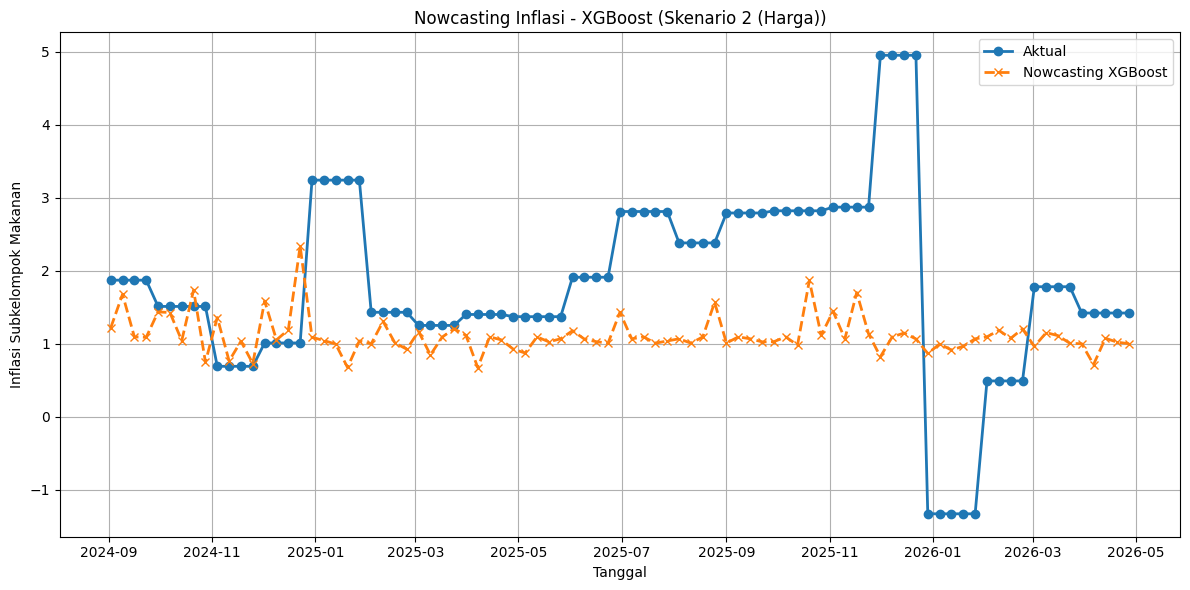

In [ ]:
# ============================================================
# PLOT NOWCASTING MODEL TERBAIK
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    hasil_nowcasting["tanggal_minggu"],
    hasil_nowcasting["aktual"],
    label="Aktual",
    marker="o",
    linewidth=2
)

plt.plot(
    hasil_nowcasting["tanggal_minggu"],
    hasil_nowcasting["nowcasting"],
    label=f"Nowcasting {nama_model_terbaik}",
    marker="x",
    linestyle="--",
    linewidth=2
)

plt.title(
    f"Nowcasting Inflasi - {nama_model_terbaik} "
    f"({nama_skenario_terbaik})"
)

plt.xlabel("Tanggal")
plt.ylabel("Inflasi Subkelompok Makanan")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### SHAP Analysis for Skenario 2 (Harga)


EXPLAINABLE AI (SHAP) - XGBOOST TERBAIK

HASIL EVALUASI XGBOOST:


,Skenario,MIDAS_RMSE,XGB_RMSE,MIDAS_MAE,XGB_MAE,MIDAS_MAPE,XGB_MAPE,MIDAS_sMAPE,XGB_sMAPE
0,Skenario 2 (Harga),1.495974,1.456444,1.150884,1.114278,56.872358,55.511711,71.986426,66.910742
1,Skenario 1 (Iklim),1.763531,1.667653,1.390172,1.367878,75.486169,65.191225,90.814832,91.232747
2,Skenario 3 (Kombinasi),1.833632,1.716182,1.459721,1.419247,82.511126,68.452804,92.080570,98.294612



Skema XGBoost terbaik: Skenario 2 (Harga)

Data yang digunakan untuk SHAP:
Jumlah observasi : 87
Jumlah variabel  : 70

Variabel:
['Beras_Hari_1', 'Beras_Hari_2', 'Beras_Hari_3', 'Beras_Hari_4', 'Beras_Hari_5', 'Beras_Hari_6', 'Beras_Hari_7', 'Daging Ayam_Hari_1', 'Daging Ayam_Hari_2', 'Daging Ayam_Hari_3', 'Daging Ayam_Hari_4', 'Daging Ayam_Hari_5', 'Daging Ayam_Hari_6', 'Daging Ayam_Hari_7', 'Daging Sapi_Hari_1', 'Daging Sapi_Hari_2', 'Daging Sapi_Hari_3', 'Daging Sapi_Hari_4', 'Daging Sapi_Hari_5', 'Daging Sapi_Hari_6', 'Daging Sapi_Hari_7', 'Telur Ayam_Hari_1', 'Telur Ayam_Hari_2', 'Telur Ayam_Hari_3', 'Telur Ayam_Hari_4', 'Telur Ayam_Hari_5', 'Telur Ayam_Hari_6', 'Telur Ayam_Hari_7', 'Bawang Merah_Hari_1', 'Bawang Merah_Hari_2', 'Bawang Merah_Hari_3', 'Bawang Merah_Hari_4', 'Bawang Merah_Hari_5', 'Bawang Merah_Hari_6', 'Bawang Merah_Hari_7', 'Bawang Putih_Hari_1', 'Bawang Putih_Hari_2', 'Bawang Putih_Hari_3', 'Bawang Putih_Hari_4', 'Bawang Putih_Hari_5', 'Bawang Putih_Hari_6', 'B

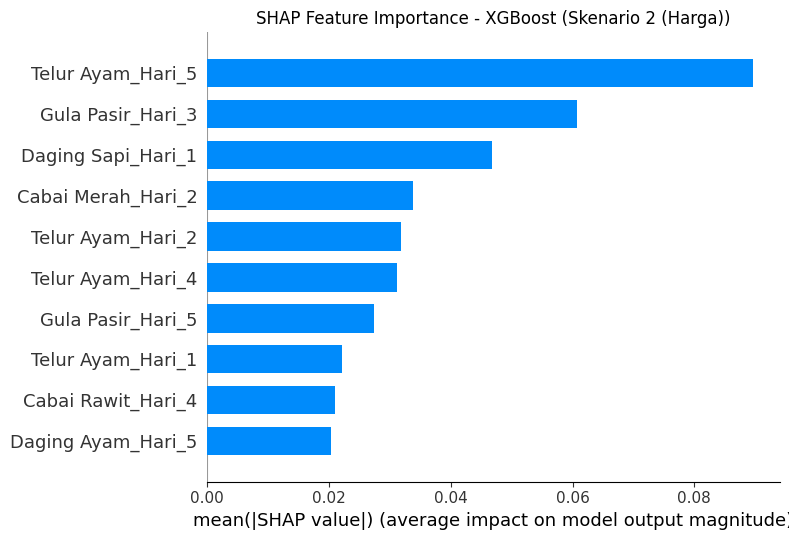

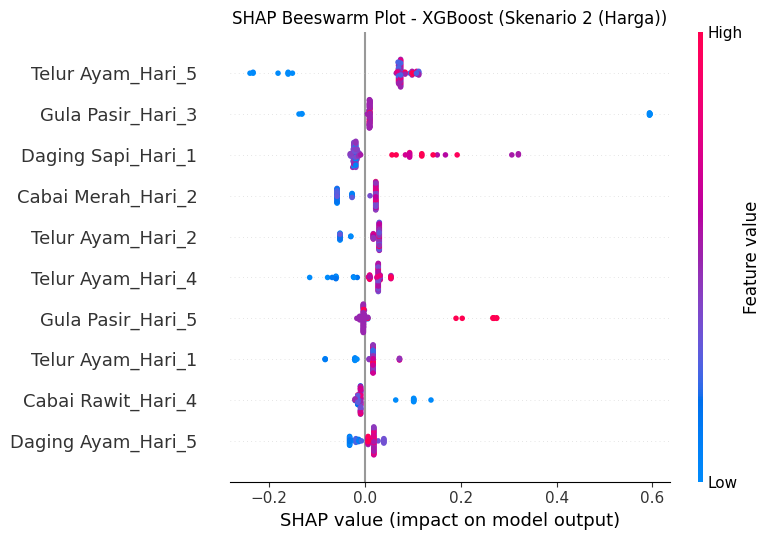

In [ ]:
# ============================================================
# SHAP - EXPLAINABLE MACHINE LEARNING
# ============================================================

import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("\n" + "="*80)
print("EXPLAINABLE AI (SHAP) - XGBOOST TERBAIK")
print("="*80)


# ============================================================
# 1. MENENTUKAN SKEMA XGBOOST TERBAIK
# ============================================================

# hasil_evaluasi berasal dari proses evaluasi 3 skenario
df_xgb = pd.DataFrame(hasil_evaluasi)

# Urutkan berdasarkan RMSE XGBoost terkecil
df_xgb = df_xgb.sort_values(
    "XGB_RMSE"
).reset_index(drop=True)

print("\nHASIL EVALUASI XGBOOST:")
display(df_xgb)


# Ambil skenario XGBoost terbaik
skema_terbaik_xgb = df_xgb.loc[0, "Skenario"]

print(
    "\nSkema XGBoost terbaik:",
    skema_terbaik_xgb
)


# ============================================================
# 2. AMBIL MODEL XGBOOST TERBAIK
# ============================================================

model_shap = model_xgb_dict[skema_terbaik_xgb]

X_shap = data_xgb_dict[
    skema_terbaik_xgb
]["X_test"].copy()


# Pastikan data numerik
X_shap = X_shap.astype(float)

# Cek missing dan inf
X_shap = X_shap.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()


print("\nData yang digunakan untuk SHAP:")
print("Jumlah observasi :", X_shap.shape[0])
print("Jumlah variabel  :", X_shap.shape[1])

print("\nVariabel:")
print(list(X_shap.columns))


# ============================================================
# 3. SHAP EXPLAINER
# ============================================================

explainer = shap.TreeExplainer(model_shap)

shap_values = explainer.shap_values(X_shap)


# ============================================================
# 4. SHAP FEATURE IMPORTANCE
# ============================================================

plt.figure(figsize=(10, 6))

shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    max_display=10,
    show=False
)

plt.title(
    f"SHAP Feature Importance - XGBoost ({skema_terbaik_xgb})"
)

plt.tight_layout()
plt.show()


# ============================================================
# 5. SHAP BEESWARM
# ============================================================

plt.figure(figsize=(10, 6))

shap.summary_plot(
    shap_values,
    X_shap,
    max_display=10,
    show=False
)

plt.title(
    f"SHAP Beeswarm Plot - XGBoost ({skema_terbaik_xgb})"
)

plt.tight_layout()
plt.show()

In [ ]:
# Data preparation for Skenario 2 (Harga)

scenario_name = "Skenario 2 (Harga)"
X_data_s2 = skenario_dict[scenario_name]

data_model_s2 = pd.concat([Y, X_data_s2], axis=1).dropna()
Y_clean_s2 = data_model_s2.iloc[:, 0]
X_clean_s2 = data_model_s2.iloc[:, 1:]

# Splitting data (80:20)
split_idx_s2 = int(len(data_model_s2) * 0.8)
X_train_s2, X_test_s2 = X_clean_s2.iloc[:split_idx_s2], X_clean_s2.iloc[split_idx_s2:]
y_train_s2, y_test_s2 = Y_clean_s2.iloc[:split_idx_s2], Y_clean_s2.iloc[split_idx_s2:]

# Normalization
scaler_s2 = StandardScaler()
X_train_scaled_s2 = pd.DataFrame(scaler_s2.fit_transform(X_train_s2), index=X_train_s2.index, columns=X_train_s2.columns)
X_test_scaled_s2 = pd.DataFrame(scaler_s2.transform(X_test_s2), index=X_test_s2.index, columns=X_test_s2.columns)

In [ ]:
# Train XGBoost model for Skenario 2 to get the best_xgb estimator

tscv_s2 = TimeSeriesSplit(n_splits=5)
param_grid_xgb_s2 = {'n_estimators': [50, 100, 200], 'max_depth': [2, 3, 5], 'learning_rate': [0.01, 0.05, 0.1]}

xgb_model_s2 = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)
grid_search_xgb_s2 = GridSearchCV(estimator=xgb_model_s2, param_grid=param_grid_xgb_s2, cv=tscv_s2, scoring='neg_root_mean_squared_error', verbose=0, n_jobs=-1)
grid_search_xgb_s2.fit(X_train_scaled_s2, y_train_s2)

best_xgb = grid_search_xgb_s2.best_estimator_ # Overwrite global best_xgb for SHAP analysis
X_test_scaled = X_test_scaled_s2 # Overwrite global X_test_scaled for SHAP analysis

print(f"Best XGBoost parameters for {scenario_name}: {grid_search_xgb_s2.best_params_}")

Best XGBoost parameters for Skenario 2 (Harga): {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 100}



MEMULAI EXPLAINABLE AI (SHAP) UNTUK MODEL XGBOOST TERBAIK


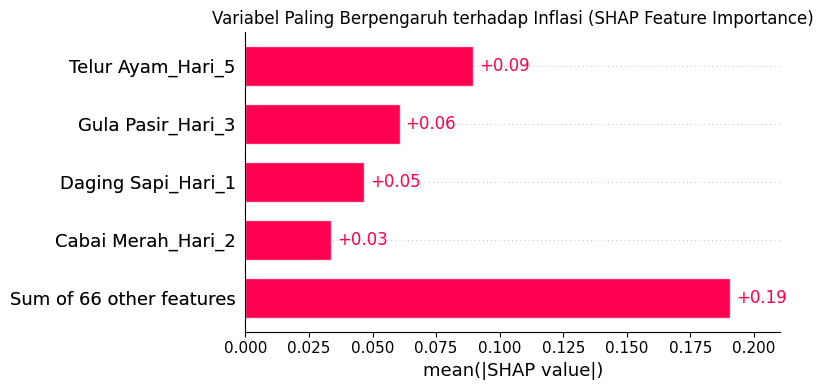

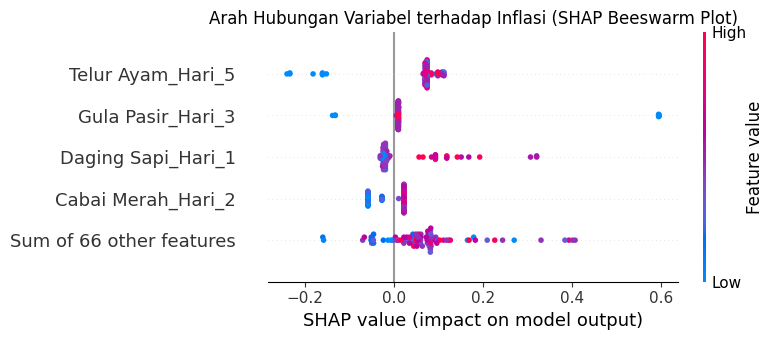

In [ ]:
# Pastikan Anda sudah install:
import shap

print("\n" + "="*80)
print("MEMULAI EXPLAINABLE AI (SHAP) UNTUK MODEL XGBOOST TERBAIK")
print("="*80)

# Menggunakan model XGBoost dari Skenario 2 (Harga) yang sudah dilatih
# Asumsi: Variabel 'best_xgb' dan 'X_test_scaled' berasal dari Skenario 2
explainer = shap.Explainer(best_xgb)
shap_values = explainer(X_test_scaled)

# 1. SHAP BAR PLOT (Mencari Variabel Paling Berpengaruh)
plt.figure(figsize=(10, 6))
plt.title("Variabel Paling Berpengaruh terhadap Inflasi (SHAP Feature Importance)")
shap.plots.bar(shap_values, max_display=5, show=False)
plt.tight_layout()
plt.show()

# 2. SHAP SUMMARY PLOT / BEESWARM (Melihat Arah Hubungan)
plt.figure(figsize=(10, 6))
plt.title("Arah Hubungan Variabel terhadap Inflasi (SHAP Beeswarm Plot)")
shap.plots.beeswarm(shap_values, max_display=5, show=False)
plt.tight_layout()
plt.show()

SEMUA FEATURE IMPORTANCE BERDASARKAN SHAP
             Feature     SHAP
   Telur Ayam_Hari_5 0.089588
   Gula Pasir_Hari_3 0.060756
  Daging Sapi_Hari_1 0.046823
  Cabai Merah_Hari_2 0.033817
   Telur Ayam_Hari_2 0.031825
   Telur Ayam_Hari_4 0.031124
   Gula Pasir_Hari_5 0.027424
   Telur Ayam_Hari_1 0.022199
  Cabai Rawit_Hari_4 0.020993
  Daging Ayam_Hari_5 0.020387
        Beras_Hari_4 0.010652
 Bawang Putih_Hari_2 0.008628
  Daging Ayam_Hari_1 0.005080
  Cabai Merah_Hari_5 0.004004
   Gula Pasir_Hari_4 0.002514
 Bawang Merah_Hari_5 0.002270
  Cabai Rawit_Hari_2 0.001867
  Daging Ayam_Hari_4 0.000892
  Daging Sapi_Hari_5 0.000886
        Beras_Hari_1 0.000000
        Beras_Hari_3 0.000000
        Beras_Hari_2 0.000000
        Beras_Hari_6 0.000000
        Beras_Hari_5 0.000000
  Daging Sapi_Hari_7 0.000000
  Daging Sapi_Hari_4 0.000000
  Daging Sapi_Hari_2 0.000000
   Telur Ayam_Hari_7 0.000000
   Telur Ayam_Hari_6 0.000000
   Telur Ayam_Hari_3 0.000000
 Bawang Merah_Hari_2 0.00000

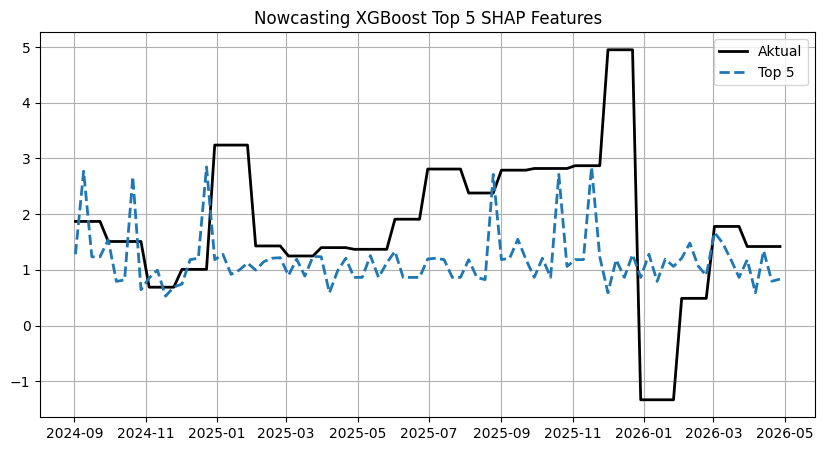


XGBOOST DENGAN TOP 10 SHAP FEATURES

Feature yang digunakan:
['Telur Ayam_Hari_5', 'Gula Pasir_Hari_3', 'Daging Sapi_Hari_1', 'Cabai Merah_Hari_2', 'Telur Ayam_Hari_2', 'Telur Ayam_Hari_4', 'Gula Pasir_Hari_5', 'Telur Ayam_Hari_1', 'Cabai Rawit_Hari_4', 'Daging Ayam_Hari_5']
RMSE  : 1.4469
MAE   : 1.0896
MAPE  : 57.6918
sMAPE : 64.9423


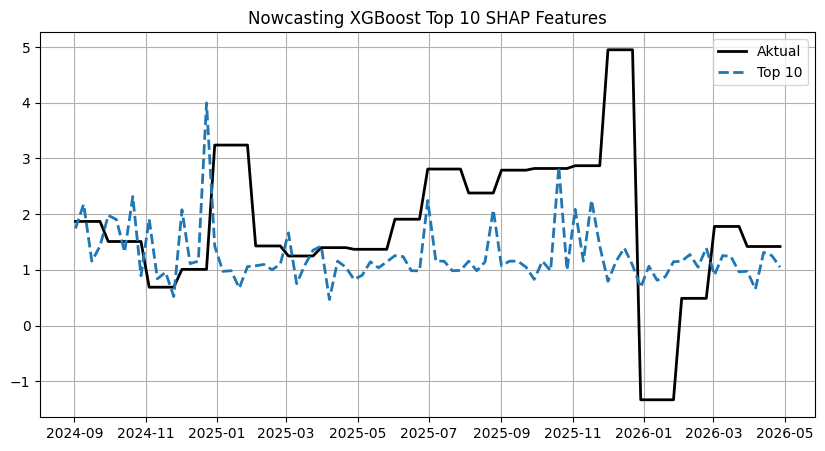


XGBOOST DENGAN TOP 15 SHAP FEATURES

Feature yang digunakan:
['Telur Ayam_Hari_5', 'Gula Pasir_Hari_3', 'Daging Sapi_Hari_1', 'Cabai Merah_Hari_2', 'Telur Ayam_Hari_2', 'Telur Ayam_Hari_4', 'Gula Pasir_Hari_5', 'Telur Ayam_Hari_1', 'Cabai Rawit_Hari_4', 'Daging Ayam_Hari_5', 'Beras_Hari_4', 'Bawang Putih_Hari_2', 'Daging Ayam_Hari_1', 'Cabai Merah_Hari_5', 'Gula Pasir_Hari_4']
RMSE  : 1.4403
MAE   : 1.1016
MAPE  : 61.8508
sMAPE : 65.3527


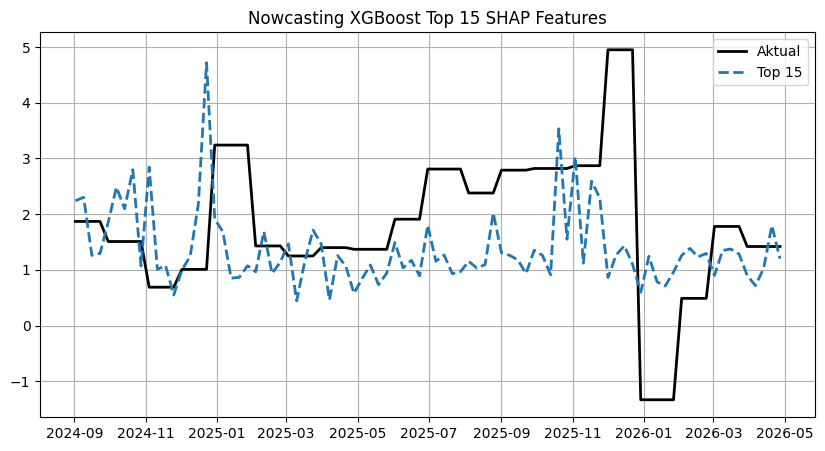


XGBOOST DENGAN TOP 20 SHAP FEATURES

Feature yang digunakan:
['Telur Ayam_Hari_5', 'Gula Pasir_Hari_3', 'Daging Sapi_Hari_1', 'Cabai Merah_Hari_2', 'Telur Ayam_Hari_2', 'Telur Ayam_Hari_4', 'Gula Pasir_Hari_5', 'Telur Ayam_Hari_1', 'Cabai Rawit_Hari_4', 'Daging Ayam_Hari_5', 'Beras_Hari_4', 'Bawang Putih_Hari_2', 'Daging Ayam_Hari_1', 'Cabai Merah_Hari_5', 'Gula Pasir_Hari_4', 'Bawang Merah_Hari_5', 'Cabai Rawit_Hari_2', 'Daging Ayam_Hari_4', 'Daging Sapi_Hari_5', 'Beras_Hari_1']
RMSE  : 1.4762
MAE   : 1.1326
MAPE  : 59.7131
sMAPE : 67.5601


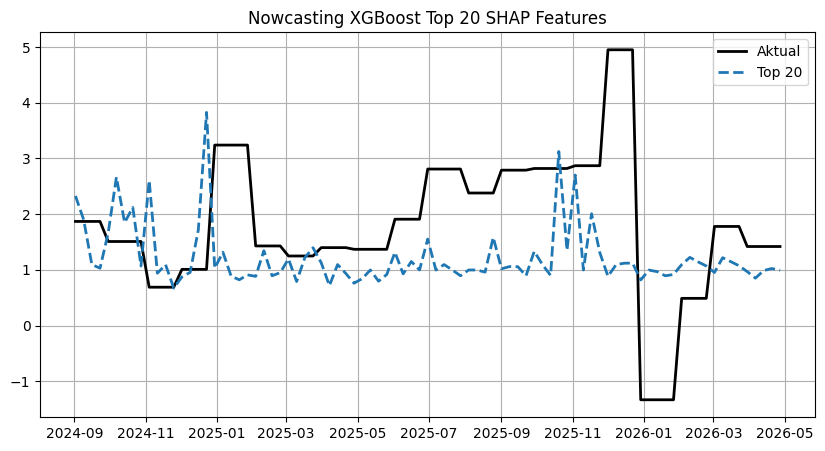


XGBOOST DENGAN TOP 25 SHAP FEATURES

Feature yang digunakan:
['Telur Ayam_Hari_5', 'Gula Pasir_Hari_3', 'Daging Sapi_Hari_1', 'Cabai Merah_Hari_2', 'Telur Ayam_Hari_2', 'Telur Ayam_Hari_4', 'Gula Pasir_Hari_5', 'Telur Ayam_Hari_1', 'Cabai Rawit_Hari_4', 'Daging Ayam_Hari_5', 'Beras_Hari_4', 'Bawang Putih_Hari_2', 'Daging Ayam_Hari_1', 'Cabai Merah_Hari_5', 'Gula Pasir_Hari_4', 'Bawang Merah_Hari_5', 'Cabai Rawit_Hari_2', 'Daging Ayam_Hari_4', 'Daging Sapi_Hari_5', 'Beras_Hari_1', 'Beras_Hari_3', 'Beras_Hari_2', 'Beras_Hari_6', 'Beras_Hari_5', 'Daging Sapi_Hari_7']
RMSE  : 1.4742
MAE   : 1.1295
MAPE  : 59.2260
sMAPE : 67.3215


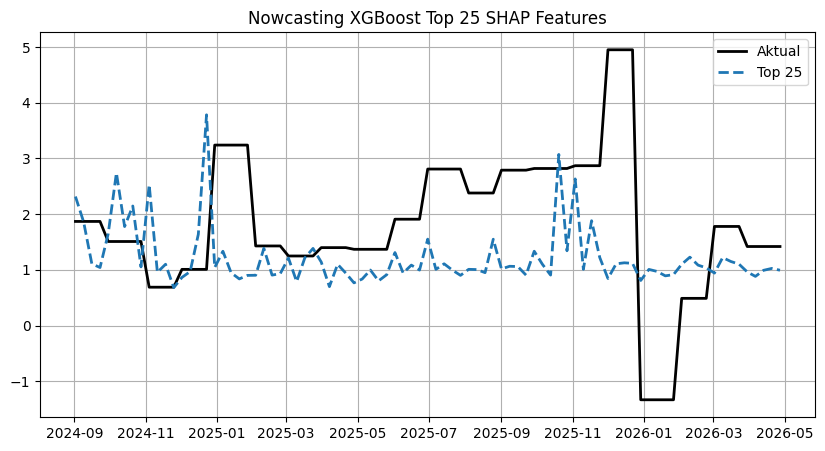


XGBOOST DENGAN TOP 30 SHAP FEATURES

Feature yang digunakan:
['Telur Ayam_Hari_5', 'Gula Pasir_Hari_3', 'Daging Sapi_Hari_1', 'Cabai Merah_Hari_2', 'Telur Ayam_Hari_2', 'Telur Ayam_Hari_4', 'Gula Pasir_Hari_5', 'Telur Ayam_Hari_1', 'Cabai Rawit_Hari_4', 'Daging Ayam_Hari_5', 'Beras_Hari_4', 'Bawang Putih_Hari_2', 'Daging Ayam_Hari_1', 'Cabai Merah_Hari_5', 'Gula Pasir_Hari_4', 'Bawang Merah_Hari_5', 'Cabai Rawit_Hari_2', 'Daging Ayam_Hari_4', 'Daging Sapi_Hari_5', 'Beras_Hari_1', 'Beras_Hari_3', 'Beras_Hari_2', 'Beras_Hari_6', 'Beras_Hari_5', 'Daging Sapi_Hari_7', 'Daging Sapi_Hari_4', 'Daging Sapi_Hari_2', 'Telur Ayam_Hari_7', 'Telur Ayam_Hari_6', 'Telur Ayam_Hari_3']
RMSE  : 1.4515
MAE   : 1.0861
MAPE  : 58.1651
sMAPE : 64.7995


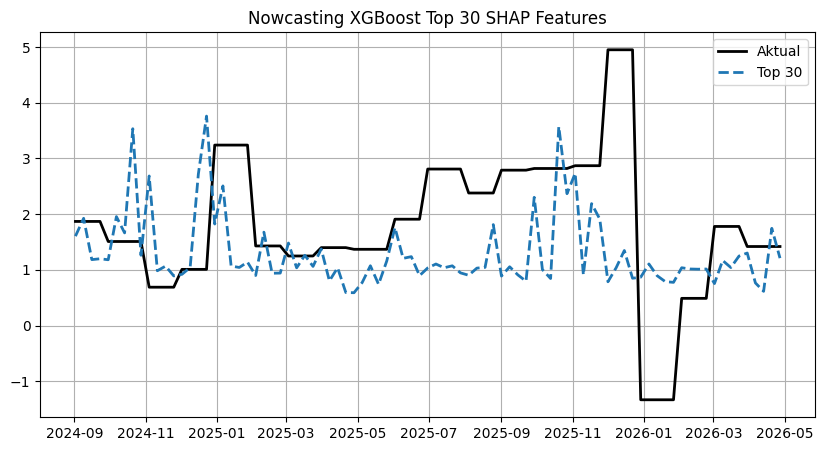



PERBANDINGAN HASIL
           Model  Jumlah Feature      RMSE       MAE       MAPE      sMAPE
0  Semua Feature              70  1.456444  1.114278  55.511711  66.910742
1     Top 5 SHAP               5  1.464110  1.098449  55.431859  66.018288
2    Top 10 SHAP              10  1.446853  1.089648  57.691776  64.942327
3    Top 15 SHAP              15  1.440266  1.101591  61.850775  65.352672
4    Top 20 SHAP              20  1.476223  1.132585  59.713086  67.560111
5    Top 25 SHAP              25  1.474203  1.129476  59.225955  67.321549
6    Top 30 SHAP              30  1.451529  1.086147  58.165119  64.799509


In [ ]:
# ============================================================
# RETRAIN XGBOOST DENGAN TOP N SHAP FEATURES
# ============================================================

from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# ---------------------------------------
# Hitung Mean |SHAP|
# ---------------------------------------
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)

importance = pd.DataFrame({
    "Feature": X_test_scaled.columns,
    "SHAP": mean_abs_shap
}).sort_values(by="SHAP", ascending=False)

print("="*80)
print("SEMUA FEATURE IMPORTANCE BERDASARKAN SHAP")
print("="*80)
print(importance.to_string(index=False))


hasil_shap_selection = []

# ======================================
# Coba Top 5, Top 10, Top 15 sd Top 30
# ======================================
for top_n in [5, 10, 15, 20, 25, 30]:

    print("\n"+"="*80)
    print(f"XGBOOST DENGAN TOP {top_n} SHAP FEATURES")
    print("="*80)

    # -----------------------------
    # Ambil fitur terbaik
    # -----------------------------
    selected_features = importance.head(top_n)["Feature"].tolist()

    print("\nFeature yang digunakan:")
    print(selected_features)

    # -----------------------------
    # Dataset baru
    # -----------------------------
    X_train_top = X_train_scaled_s2[selected_features]
    X_test_top = X_test_scaled_s2[selected_features]

    # -----------------------------
    # Grid Search
    # -----------------------------
    xgb_model = xgb.XGBRegressor(
        objective='reg:squarederror',
        random_state=42
    )

    grid_search = GridSearchCV(
        estimator=xgb_model,
        param_grid=param_grid_xgb_s2,
        cv=tscv_s2,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )

    grid_search.fit(X_train_top, y_train_s2)

    best_model = grid_search.best_estimator_

    # -----------------------------
    # Prediksi
    # -----------------------------
    y_pred = best_model.predict(X_test_top)

    # -----------------------------
    # Evaluasi
    # -----------------------------
    rmse = np.sqrt(mean_squared_error(y_test_s2, y_pred))
    mae = mean_absolute_error(y_test_s2, y_pred)
    mape = mean_absolute_percentage_error(y_test_s2, y_pred)*100
    smape = np.mean(
        2*np.abs(y_pred-y_test_s2) /
        (np.abs(y_test_s2)+np.abs(y_pred)+1e-8)
    )*100

    print(f"RMSE  : {rmse:.4f}")
    print(f"MAE   : {mae:.4f}")
    print(f"MAPE  : {mape:.4f}")
    print(f"sMAPE : {smape:.4f}")

    hasil_shap_selection.append({
        "Model":f"Top {top_n} SHAP",
        "Jumlah Feature":top_n,
        "RMSE":rmse,
        "MAE":mae,
        "MAPE":mape,
        "sMAPE":smape
    })

    # -----------------------------
    # Plot hasil prediksi
    # -----------------------------
    plot_dates = pd.to_datetime(
        y_test_s2.index.map(lambda x: f"{x[:4]}-W{x[-2:]}-1"),
        format="%G-W%V-%u"
    )

    plt.figure(figsize=(10,5))

    plt.plot(
        plot_dates,
        y_test_s2.values,
        color="black",
        linewidth=2,
        label="Aktual"
    )

    plt.plot(
        plot_dates,
        y_pred,
        linestyle="--",
        linewidth=2,
        label=f"Top {top_n}"
    )

    plt.title(f"Nowcasting XGBoost Top {top_n} SHAP Features")
    plt.legend()
    plt.grid(True)
    plt.show()


# ============================================================
# PERBANDINGAN
# ============================================================

hasil_awal = pd.DataFrame([{
    "Model":"Semua Feature",
    "Jumlah Feature":X_train_scaled_s2.shape[1],
    "RMSE":1.456444,   # ganti dengan eval_xgb skenario harga
    "MAE":1.114278,
    "MAPE":55.511711,
    "sMAPE":66.910742
}])

hasil_shap_selection = pd.DataFrame(hasil_shap_selection)

hasil_akhir = pd.concat(
    [hasil_awal, hasil_shap_selection],
    ignore_index=True
)

print("\n")
print("="*80)
print("PERBANDINGAN HASIL")
print("="*80)

print(hasil_akhir)

### Implementasi Fitur Waktu (Sinusoidal Month & Week) ke Semua Skenario

In [ ]:
import numpy as np
import pandas as pd

# --- 1. Generate Time-based Features (sin/cos of month, week) ---
def get_datetime_from_isoweek(iso_week_str):
    year, week = int(iso_week_str.split('-W')[0]), int(iso_week_str.split('-W')[1])
    # Use day 4 (Thursday) to reliably get the month for the given ISO week
    return pd.to_datetime(f"{year}-W{week}-4", format="%G-W%V-%u")

# Apply this function to the index of df_master to get datetime objects
# This creates a Series with ISO_YearWeek as index and datetime objects as values
datetime_series_from_iso = df_master.index.to_series().apply(get_datetime_from_isoweek)

# Explicitly convert the values of the Series to datetime objects, coercing errors to NaT
datetime_series_from_iso = pd.to_datetime(datetime_series_from_iso, errors='coerce')

# Identify and remove any NaT values and align df_master
if datetime_series_from_iso.isna().any():
    valid_iso_weeks = datetime_series_from_iso.dropna().index # This gives the ISO_YearWeek labels
    datetime_series_from_iso = datetime_series_from_iso.loc[valid_iso_weeks]
    df_master = df_master.loc[valid_iso_weeks] # Ensure df_master is aligned to these valid ISO_YearWeeks

# Now, df_master.index and datetime_series_from_iso.index are guaranteed to be the same
# and datetime_series_from_iso contains no NaT values.

df_time_features_all = pd.DataFrame(index=df_master.index)

# Month features
# Access .dt accessor for the Series of datetime objects
df_time_features_all['month'] = datetime_series_from_iso.dt.month
df_time_features_all['sin_month'] = np.sin(2 * np.pi * df_time_features_all['month'] / 12)
df_time_features_all['cos_month'] = np.cos(2 * np.pi * df_time_features_all['month'] / 12)

# Week of year features (ISO week)
# isocalendar().week returns a Series directly, correctly indexed.
df_time_features_all['week_of_year'] = datetime_series_from_iso.dt.isocalendar().week.astype(int)
df_time_features_all['sin_week'] = np.sin(2 * np.pi * df_time_features_all['week_of_year'] / 52)
df_time_features_all['cos_week'] = np.cos(2 * np.pi * df_time_features_all['week_of_year'] / 52)

# Select the relevant time features
selected_time_features = ['month', 'sin_month', 'cos_month', 'week_of_year', 'sin_week', 'cos_week']
df_time_features_all = df_time_features_all[selected_time_features]

# --- 2. Construct New X datasets for all scenarios with time features ---
# Use columns from the current df_master, which is already cleaned and aligned.
# X_iklim_midas.columns and X_harga_midas.columns are used to select columns from df_master.
# These will correctly get the original climate/price data that was combined into df_master.
X_iklim_with_time = pd.concat([df_master[X_iklim_midas.columns], df_time_features_all], axis=1).dropna()
X_harga_with_time = pd.concat([df_master[X_harga_midas.columns], df_time_features_all], axis=1).dropna()
X_kombinasi_with_time = pd.concat([df_master[X_iklim_midas.columns], df_master[X_harga_midas.columns], df_time_features_all], axis=1).dropna()

# Y_aligned is derived from the cleaned df_master, so it's correctly aligned with the X_data.
Y_aligned = df_master['Inflasi Subkelompok Makanan']

# The reindex is technically redundant if everything is aligned, but harmless.
Y_iklim_with_time = Y_aligned.reindex(X_iklim_with_time.index)
Y_harga_with_time = Y_aligned.reindex(X_harga_with_time.index)
Y_kombinasi_with_time = Y_aligned.reindex(X_kombinasi_with_time.index)

skenario_dict_with_time = {
    "Skenario 1 (Iklim + Time)": (X_iklim_with_time, Y_iklim_with_time),
    "Skenario 2 (Harga + Time)": (X_harga_with_time, Y_harga_with_time),
    "Skenario 3 (Kombinasi + Time)": (X_kombinasi_with_time, Y_kombinasi_with_time)
}

print("Successfully prepared new scenarios with time-based features.")

Successfully prepared new scenarios with time-based features.


### Evaluasi Model MIDAS dan XGBoost dengan Fitur Waktu Baru


MENJALANKAN SKENARIO 1 (IKLIM + TIME) (DENGAN FITUR WAKTU)
--- Evaluasi MIDAS BASIC - Skenario 1 (Iklim + Time) ---
RMSE : 1.8757 | MAE : 1.5280 | MAPE : 85.0671% | sMAPE : 100.0421%
--- Evaluasi XGBOOST ML - Skenario 1 (Iklim + Time) ---
RMSE : 1.6836 | MAE : 1.3916 | MAPE : 67.3131% | sMAPE : 94.7009%


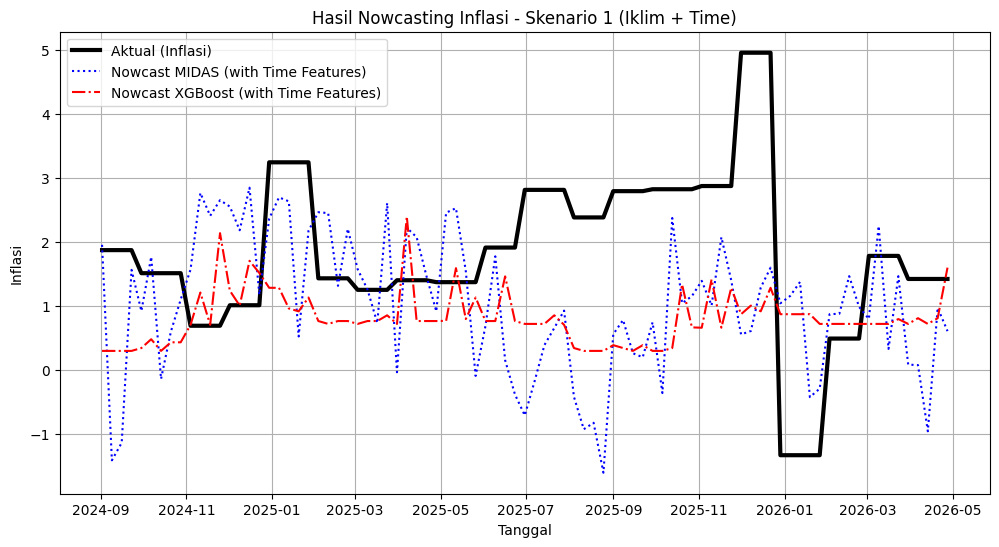


MENJALANKAN SKENARIO 2 (HARGA + TIME) (DENGAN FITUR WAKTU)
--- Evaluasi MIDAS BASIC - Skenario 2 (Harga + Time) ---
RMSE : 1.8961 | MAE : 1.5564 | MAPE : 85.2609% | sMAPE : 103.1416%
--- Evaluasi XGBOOST ML - Skenario 2 (Harga + Time) ---
RMSE : 1.6795 | MAE : 1.2922 | MAPE : 64.2490% | sMAPE : 84.5573%


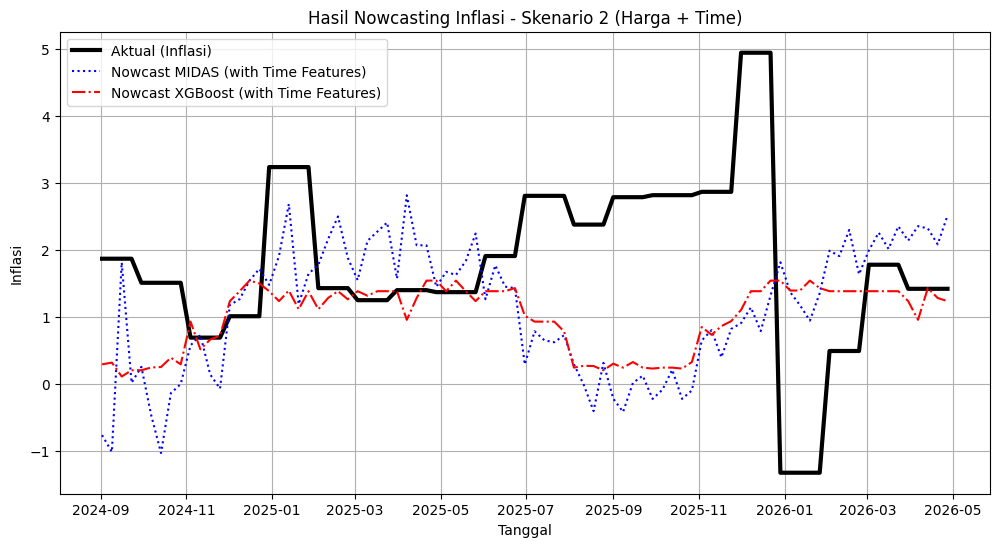


MENJALANKAN SKENARIO 3 (KOMBINASI + TIME) (DENGAN FITUR WAKTU)
--- Evaluasi MIDAS BASIC - Skenario 3 (Kombinasi + Time) ---
RMSE : 1.9323 | MAE : 1.5799 | MAPE : 89.7599% | sMAPE : 102.6440%
--- Evaluasi XGBOOST ML - Skenario 3 (Kombinasi + Time) ---
RMSE : 1.6881 | MAE : 1.3910 | MAPE : 67.2311% | sMAPE : 94.8022%


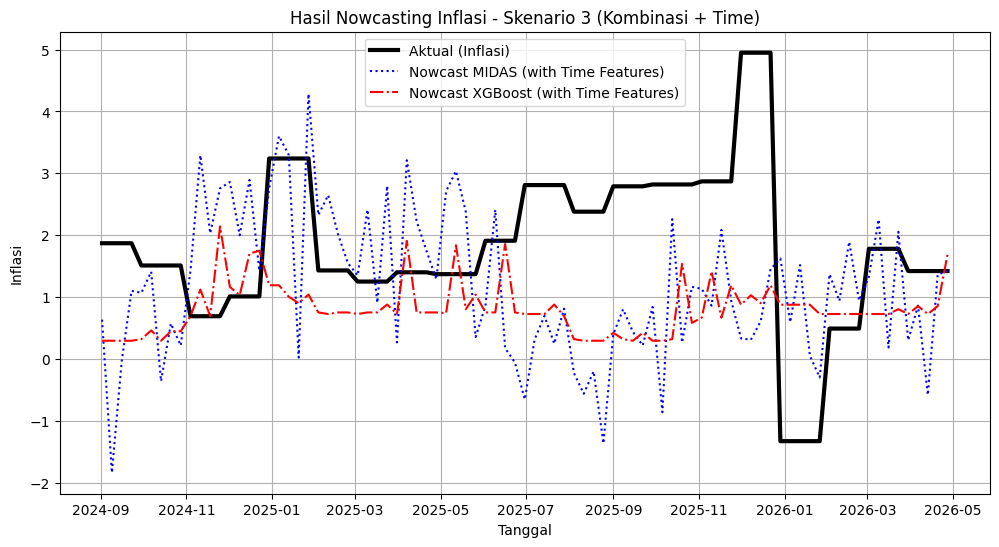


KESIMPULAN PERBANDINGAN MODEL (Evaluasi Metrik) dengan Fitur Waktu
                     Skenario  MIDAS_RMSE  XGB_RMSE  MIDAS_MAE  XGB_MAE  MIDAS_MAPE  XGB_MAPE  MIDAS_sMAPE  XGB_sMAPE
    Skenario 1 (Iklim + Time)    1.875677  1.683594   1.528023 1.391642   85.067112 67.313099   100.042084  94.700889
    Skenario 2 (Harga + Time)    1.896140  1.679538   1.556427 1.292176   85.260941 64.248958   103.141577  84.557329
Skenario 3 (Kombinasi + Time)    1.932332  1.688101   1.579945 1.391043   89.759916 67.231064   102.644039  94.802161


In [ ]:
def evaluate_model(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    smape = np.mean(2.0 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)) * 100
    print(f"--- Evaluasi {model_name} ---")
    print(f"RMSE : {rmse:.4f} | MAE : {mae:.4f} | MAPE : {mape:.4f}% | sMAPE : {smape:.4f}%")
    return {'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'sMAPE': smape}

# Initialize a new list for evaluation results for scenarios with time features
hasil_evaluasi_with_time = []

# Best parameters for Skenario 2 (Harga) from previous run, used for all XGBoost models
best_xgb_params = {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 100}

for nama_skenario_time, (X_data_time, Y_data_time) in skenario_dict_with_time.items():
    print(f"\n{'='*70}\nMENJALANKAN {nama_skenario_time.upper()} (DENGAN FITUR WAKTU)\n{'='*70}")

    # Ensure X and Y are aligned and have no NaNs
    data_model_time = pd.concat([Y_data_time, X_data_time], axis=1).dropna()
    Y_clean_time = data_model_time.iloc[:, 0]
    X_clean_time = data_model_time.iloc[:, 1:]

    # Splitting Data (80:20)
    split_idx_time = int(len(data_model_time) * 0.8)
    X_train_time, X_test_time = X_clean_time.iloc[:split_idx_time], X_clean_time.iloc[split_idx_time:]
    y_train_time, y_test_time = Y_clean_time.iloc[:split_idx_time], Y_clean_time.iloc[split_idx_time:]

    # Normalization
    scaler_time = StandardScaler()
    X_train_scaled_time = pd.DataFrame(scaler_time.fit_transform(X_train_time), index=X_train_time.index, columns=X_train_time.columns)
    X_test_scaled_time = pd.DataFrame(scaler_time.transform(X_test_time), index=X_test_time.index, columns=X_test_time.columns)

    # ------------------------------------------
    # MODEL 1: MIDAS BASIC (U-MIDAS dg OLS) with Time Features
    # ------------------------------------------
    X_train_midas_time = sm.add_constant(X_train_scaled_time)
    X_test_midas_time = sm.add_constant(X_test_scaled_time)

    model_midas_time = sm.OLS(y_train_time, X_train_midas_time).fit()
    y_pred_midas_time = model_midas_time.predict(X_test_midas_time)
    eval_midas_time = evaluate_model(y_test_time, y_pred_midas_time, f"MIDAS BASIC - {nama_skenario_time}")

    # ------------------------------------------
    # MODEL 2: XGBOOST with Time Features
    # ------------------------------------------
    xgb_model_time = xgb.XGBRegressor(objective='reg:squarederror',
                                     random_state=42,
                                     **best_xgb_params)
    xgb_model_time.fit(X_train_scaled_time, y_train_time)

    y_pred_xgb_time = xgb_model_time.predict(X_test_scaled_time)
    eval_xgb_time = evaluate_model(y_test_time, y_pred_xgb_time, f"XGBOOST ML - {nama_skenario_time}")

    # Store evaluation results
    hasil_evaluasi_with_time.append({
        'Skenario': nama_skenario_time,
        'MIDAS_RMSE': eval_midas_time['RMSE'], 'XGB_RMSE': eval_xgb_time['RMSE'],
        'MIDAS_MAE': eval_midas_time['MAE'], 'XGB_MAE': eval_xgb_time['MAE'],
        'MIDAS_MAPE': eval_midas_time['MAPE'], 'XGB_MAPE': eval_xgb_time['MAPE'],
        'MIDAS_sMAPE': eval_midas_time['sMAPE'], 'XGB_sMAPE': eval_xgb_time['sMAPE']
    })

    # Visualization
    plot_dates_time = pd.to_datetime(y_test_time.index.map(lambda x: f"{x[:4]}-W{x[-2:]}-1"), format="%G-W%V-%u")

    plt.figure(figsize=(12, 6))
    plt.plot(plot_dates_time, y_test_time.values, label='Aktual (Inflasi)', color='black', linewidth=3)
    plt.plot(plot_dates_time, y_pred_midas_time, label='Nowcast MIDAS (with Time Features)', color='blue', linestyle=':')
    plt.plot(plot_dates_time, y_pred_xgb_time, label='Nowcast XGBoost (with Time Features)', color='red', linestyle='-.')

    plt.title(f'Hasil Nowcasting Inflasi - {nama_skenario_time}')
    plt.xlabel('Tanggal')
    plt.ylabel('Inflasi')
    plt.legend()
    plt.grid(True)
    plt.show()
    plt.close() # Add this line to explicitly close the figure

print("\n" + "="*80)
print("KESIMPULAN PERBANDINGAN MODEL (Evaluasi Metrik) dengan Fitur Waktu")
print("="*80)
df_perbandingan_with_time = pd.DataFrame(hasil_evaluasi_with_time)
print(df_perbandingan_with_time.to_string(index=False))